In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# read and process dataset

path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx - TextReading_Included.csv"
df = pd.read_csv(path, usecols={"topic": str, "Title": str, "Year": int, "Source": str})
df = df[df.topic.notna()]
df.reset_index(drop=True, inplace=True)

df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)
df

,topic,Title,Year,Source
0,[Model],Generating accessible multi-occupancy floor pl...,2025,Scopus
1,[Model],An Attention-Based Constrained Diffusion Model...,2025,Scopus
2,[Model],Floorplan-Diffusion: Automatic Floor Plan Gene...,2025,Scopus
3,[Model],Boundary Conditioned Floor Layout Generation w...,2024,Scopus
4,[Model],Cons2Plan: Vector Floorplan Generation from Va...,2024,Scopus
...,...,...,...,...
74,"[Model, Dataset]",PlanNet: A Generative Model for Component-Base...,2024,Scopus
75,"[Model, Dataset]",Automated building layout generation using dee...,2023,Scopus
76,"[Model, Dataset]",Tell2Design: A Dataset for Language-Guided Flo...,2023,Scopus
77,"[Model, Dataset]",Data-driven interior plan generation for resid...,2019,Scopus


In [4]:
# Figure: papers per Year

counts = df.groupby(['Year', 'Source']).size().unstack(fill_value=0)
counts = counts.sort_index()
counts

Source,Scopus,arXiv
Year,,
2019,1,0
2020,4,0
2021,1,0
2022,7,0
2023,8,4
2024,18,4
2025,28,4


<Axes: xlabel='Year', ylabel='# papers'>

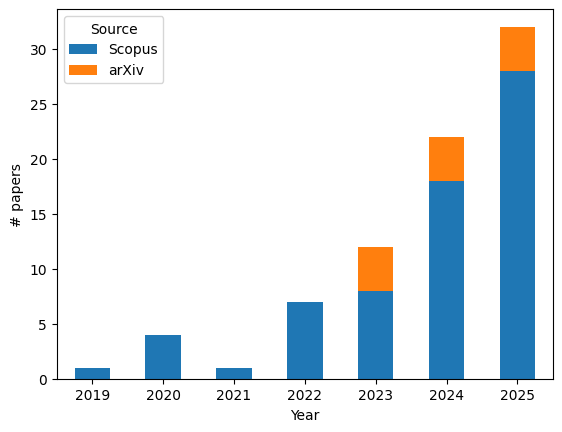

In [5]:
counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)

In [7]:
# Novelty

df.topic.value_counts().sort_index()

topic
[Dataset]                        2
[Dataset, Evaluation]            1
[Evaluation]                     5
[Model]                         58
[Model, Dataset]                 9
[Model, Dataset, Evaluation]     3
[Model, Evaluation]              1
Name: count, dtype: int64